# Perplexity vs. Loaded KV

单独复现 `motivation_ppl_vs_loaded_kv.pdf`。代码提取自
`论文画图/Motivation/plot_motivation_figures.ipynb` 的 PPL 绘图部分。

只绘制 LLaMA3 的 Quest + Top-p、DS + Top-p 和 Full Attention 参考线。
保留原始数据、p > 0 过滤、对数横轴、标注和默认样式。

使用方法：依次运行所有单元。修改第二个代码单元中的尺寸、字体、颜色、
标注阈值或数据路径后，重新运行后续单元。输出 PDF 和 300 dpi PNG 到本文件夹。

依赖：`matplotlib`、`openpyxl`；Notebook 另需 Jupyter/IPython。
如缺少依赖，可在新单元运行 `%pip install matplotlib openpyxl`。


## 1. 导入依赖与文件路径

In [1]:
from __future__ import annotations

from pathlib import Path
from openpyxl import load_workbook
import matplotlib as mpl
import matplotlib.pyplot as plt

# 一般直接从本文件夹打开；也支持从项目根目录运行。
# 如果从其他位置启动 Jupyter，请将下行改为本文件夹的绝对路径。
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()
    if not (NOTEBOOK_DIR / "TopP_ppl_KVamp.xlsx").exists():
        NOTEBOOK_DIR = NOTEBOOK_DIR / "会用到的论文图与复现" / "PerpvsLoadedKV"

INPUT_XLSX = NOTEBOOK_DIR / "TopP_ppl_KVamp.xlsx"
OUTPUT_DIR = NOTEBOOK_DIR
OUTPUT_NAME = "motivation_ppl_vs_loaded_kv"
print("Input:", INPUT_XLSX)


Input: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/PerpvsLoadedKV/TopP_ppl_KVamp.xlsx


## 2. 可修改参数与样式

In [12]:
# 常用可修改参数
FIGSIZE = (3.5, 2)  # 英寸
DPI = 300
LABEL_FONT = {"size": 10, "weight": "bold", "fontfamily": "Times New Roman"}
P_LABELS_LOW = {0.1, 0.2, 0.3}
P_LABELS_HIGH = {0.8, 0.9, 1.0}
X_LABEL = "Loaded KV tokens per decode step (log scale)"
Y_LABEL = "Perplexity (lower is better)"
PPL_STYLES = {
    "Quest + Top-p": {"color": "#2F6FBA", "marker": "o", "linestyle": "-"},
    "DS + Top-p": {"color": "#d08759", "marker": "s", "linestyle": "-"},
}

mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9,
    "axes.labelsize": 9, "axes.titlesize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.8, "lines.linewidth": 1.8, "lines.markersize": 4.5,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.bbox": "tight",
})


## 3. 读取原始数据

In [3]:
def read_sheet_block(path: Path, sheet_name: str, start_col: int) -> list[dict[str, float]]:
    """Read an 8-column sweep block from a sheet.

    start_col is 1-indexed. This supports sheets where Quest/DS blocks are
    placed side by side, with the second block using Excel headers like p.1.
    """
    workbook = load_workbook(path, data_only=True)
    if sheet_name not in workbook.sheetnames:
        raise ValueError(f"Sheet {sheet_name!r} not found in {path}")

    sheet = workbook[sheet_name]
    raw_headers = [sheet.cell(row=1, column=col).value for col in range(start_col, start_col + 8)]
    headers = [str(header).replace(".1", "") for header in raw_headers]
    required = [
        "p",
        "method",
        "ppl",
        "tokens",
        "per-head selected",
        "group union",
        "loaded KV tokens",
        "union amp",
    ]
    if headers != required:
        raise ValueError(
            f"Unexpected headers in sheet {sheet_name!r} at col {start_col}: {raw_headers}. "
            f"Expected normalized headers: {required}"
        )

    rows: list[dict[str, float]] = []
    for row_idx in range(2, sheet.max_row + 1):
        values = [sheet.cell(row=row_idx, column=col).value for col in range(start_col, start_col + 8)]
        if values[0] is None:
            continue
        rows.append(dict(zip(required, values)))
    return rows

def read_full_ppl(path: Path) -> float | None:
    """Read the full-attention PPL column if present in the workbook."""
    workbook = load_workbook(path, data_only=True)
    for sheet_name in workbook.sheetnames:
        sheet = workbook[sheet_name]
        headers = [sheet.cell(row=1, column=col).value for col in range(1, sheet.max_column + 1)]
        if "full" not in headers:
            continue
        col = headers.index("full") + 1
        for row_idx in range(2, sheet.max_row + 1):
            value = sheet.cell(row=row_idx, column=col).value
            if isinstance(value, (int, float)):
                return float(value)
    return None

def drop_boundary_point(rows: list[dict[str, float]]) -> list[dict[str, float]]:
    """Drop p=0.0 from formal plots; it is a boundary/debug point."""
    return [row for row in rows if float(row["p"]) > 0.0]

# 原表 llama3: DS 位于 A:H，Quest 位于 N:U。
# Full Attention 按原逻辑读取首个 full 列中的数值。
data = {
    "Quest + Top-p": drop_boundary_point(read_sheet_block(INPUT_XLSX, "llama3", 14)),
    "DS + Top-p": drop_boundary_point(read_sheet_block(INPUT_XLSX, "llama3", 1)),
}
full_ppl = read_full_ppl(INPUT_XLSX)
print("Full Attention PPL:", full_ppl)
for label, rows in data.items():
    print(label, "points:", len(rows))
    for row in rows:
        print(f"  p={row['p']:.1f}, loaded KV={row['loaded KV tokens']}, PPL={row['ppl']}")


Full Attention PPL: 6.44095021658267
Quest + Top-p points: 10
  p=0.1, loaded KV=357.61, PPL=64.3243
  p=0.2, loaded KV=285.88, PPL=33.9398
  p=0.3, loaded KV=288.09, PPL=21.7432
  p=0.4, loaded KV=311.4, PPL=14.9434
  p=0.5, loaded KV=365.3, PPL=11.4335
  p=0.6, loaded KV=460.51, PPL=9.8279
  p=0.7, loaded KV=632.05, PPL=9.0805
  p=0.8, loaded KV=945.77, PPL=8.4173
  p=0.9, loaded KV=1689.38, PPL=8.1761
  p=1.0, loaded KV=12627.72, PPL=8.0641
DS + Top-p points: 10
  p=0.1, loaded KV=100.3, PPL=25.5224
  p=0.2, loaded KV=124.78, PPL=13.6873
  p=0.3, loaded KV=170.26, PPL=11.4842
  p=0.4, loaded KV=225.8, PPL=9.2102
  p=0.5, loaded KV=310.17, PPL=7.8988
  p=0.6, loaded KV=443.95, PPL=7.3885
  p=0.7, loaded KV=651.77, PPL=6.9676
  p=0.8, loaded KV=1024.1, PPL=6.8329
  p=0.9, loaded KV=1918.61, PPL=6.4335
  p=1.0, loaded KV=15297.73, PPL=6.3658


## 4. 绘图与标注函数

In [70]:

# 单位为 point；正数向右、向上
P_OFFSETS = {
    "Quest + Top-p": {
        0.1: (4, -1),
        0.2: (4, 2),
        0.3: (4, 1),
        0.8: (-6, 7),
        0.9: (-6, 7),
        1.0: (-6, 7),
    },
    "DS + Top-p": {
        0.1: (4, 2),
        0.2: (4, 2),
        0.3: (4, 1),
        0.8: (0, 3),
        0.9: (0, 3),
        1.0: (-2.5, 3),
    },
}

def add_p_labels(ax, rows, labels, color, method):
    for row in rows:
        p = round(float(row["p"]), 2)
        if p not in labels:
            continue

        dx, dy = P_OFFSETS[method][p]

        ax.annotate(
            f"{p:.1f}",
            xy=(float(row["loaded KV tokens"]), float(row["ppl"])),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=8,
            color=color,
            ha="left",
            va="bottom" if dy >= 0 else "top",
        )


def plot_ppl_vs_loaded_kv(ax, data: dict[str, list[dict[str, float]]], full_ppl: float | None) -> None:
    for label, rows in data.items():
        rows = [row for row in rows if float(row["p"]) > 0.0]
        style = PPL_STYLES[label]
        x = [float(row["loaded KV tokens"]) for row in rows]
        y = [float(row["ppl"]) for row in rows]
        ax.plot(x, y, label=label, **style)
        add_p_labels(
            ax,
            rows,
            labels=P_LABELS_LOW | P_LABELS_HIGH,
            color=style["color"],
            method=label,
        )

    if full_ppl is not None:
        ax.axhline(
            full_ppl,
            color="red",
            linestyle="--",
            linewidth=1.1,
            # label=f"Full attention PPL ({full_ppl:.2f})",
            label=f"Full Attention",
            zorder=10,
        )

    # ax.set_xscale("log")
    # ax.set_xlabel(X_LABEL, fontdict=LABEL_FONT)
    # ax.set_ylabel(Y_LABEL, fontdict=LABEL_FONT)
    # # ax.set_title("(a) Perplexity vs. actual KV load")
    # ax.grid(True, which="major", color="#d0d0d0", linewidth=0.6, alpha=0.8)
    # ax.grid(True, which="minor", color="#e8e8e8", linewidth=0.4, alpha=0.5)
    
    ax.set_xscale("log")

    # 只保留三个主刻度
    ax.set_xticks([1e2, 1e3, 1e4])
    ax.set_xticklabels([r"$10^2$", r"$10^3$", r"$10^4$"])

    # 移除横轴中间的次刻度及其文字
    ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())

    ax.set_xlabel(X_LABEL, fontdict=LABEL_FONT)
    ax.set_ylabel(Y_LABEL, fontdict=LABEL_FONT)

    # 只在上述三个 x 位置绘制竖线
    ax.grid(True, which="both", axis="both",color="#d0d0d0", linewidth=0.6, alpha=0.8)
    ax.grid(
        True, which="major", axis="x",
        color="#d0d0d0", linewidth=0.6, alpha=0.8,
    )

    ax.legend(frameon=True, framealpha=0.92, fontsize=9)

## 5. 导出与预览

Saved: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/PerpvsLoadedKV/motivation_ppl_vs_loaded_kv.pdf


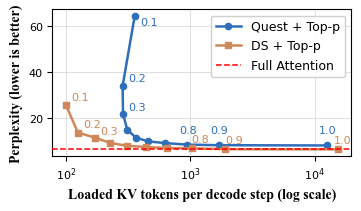

In [71]:
fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True)
plot_ppl_vs_loaded_kv(ax, data, full_ppl)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / f"{OUTPUT_NAME}.pdf")
fig.savefig(OUTPUT_DIR / f"{OUTPUT_NAME}.png", dpi=DPI)
print("Saved:", OUTPUT_DIR / f"{OUTPUT_NAME}.pdf")
plt.show()
